# Learned drum decoration for group fitness music

*Generative AI for Music, University of Amsterdam.*

**Group 3**: Giacomo Grazia, Sönke Erdmann and Arshana Ramautar

---

This notebook explains the project, plays the generated drums and shows the results. All code lives in `src/`;
the notebook only imports it. Heavy results (trained models, the 30 loops per system, the result tables and
figures) were produced by `python -m src.train` and `python -m src.evaluate` and are loaded from `output/`, so the
notebook runs top to bottom in seconds without a GPU. The dataset (3 MB) downloads automatically on first run.

# 0. Imports

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import Audio, Image, Markdown, display
from scipy.signal import resample_poly

from src.config import CHECKPOINT_DIR, CLASSES, DECORATION_CHANNELS, LISTEN_SEEDS, OUTPUT_DIR, SEEDS, skeleton_loop
from src.data import load_bars
from src.generate import add_fill, lstm_loop, rule_loop, rule_probabilities
from src.metrics import density
from src.plot_style import apply_style, decorate
from src.plots import plot_grid

apply_style()
RESULTS, AUDIO = OUTPUT_DIR / "results", OUTPUT_DIR / "audio"
LOOPS = dict(np.load(RESULTS / "loops.npz"))  # system -> (30 loops, 128 steps, 9 drums); B-D per training seed


def play(name: str, label: str = "", folder=AUDIO) -> None:
    """Show a label and an audio player for <folder>/<name>.wav (clips: 15 s, 8 bars at 128 BPM).

    Embedded at half the sample rate (22.05 kHz) to keep the notebook small; the full-quality WAVs are in output/audio.
    """
    if label:
        display(Markdown(f"**{label}**"))
    audio, sr = sf.read(folder / f"{name}.wav")
    display(Audio(resample_poly(audio, 1, 2), rate=sr // 2))


def show_loop(loop: np.ndarray, title: str, subtitle: str = "") -> None:
    """Draw one 8-bar loop (128, 9) as a drum grid."""
    fig, ax = plt.subplots(figsize=(14, 3.4))
    plot_grid(loop, ax=ax)
    decorate(fig, title, subtitle=subtitle)
    plt.show()

# 1. The idea

**Aesthetic goal: steady for the body, alive for the ear.** Workout drums whose pulse never wavers, so a class can
move as one, but whose groove keeps shifting like a human drummer playing for the room, rather than one bar looping
like a drum machine.

Group fitness needs both halves. *Steady*: an instructor cues moves on the beat, and a class of thirty people only
moves together if the kick lands on every beat and the snare on 2 and 4, without exception. *Alive*: a class lasts an
hour, and a single bar looped for an hour is tiring to listen to. Human drummers solve this by repeating a groove
and varying it in small ways, more at the end of a phrase.

We split the drums into two parts:

- the **skeleton**: kick on every beat ("four on the floor") and snare on beats 2 and 4. This must be reliable.
- the **decoration**: hi-hats, toms, crash and ride. This is where variation lives.

**Research question:** with kick and snare fixed, does a model trained on human drumming produce more varied drums
than hand-written rules? It has two parts:

| Part | Comparison | "Yes" means |
|---|---|---|
| **Steady:** do we need the constraint to keep the pulse? | free model B vs constrained model C | B's exact-bar rate is clearly below 100% |
| **Alive:** is the constrained model more varied than rules? | rules A vs constrained model C, at similar density | C changes over time more like real drumming than A (repeats bars, varies in bursts), its diversity is not lower, it does not just play more notes, and listeners find it more interesting |

**Four systems**, all on 8-bar loops at 128 BPM, 30 loops each (seeds 0-29):

| System | What it does |
|---|---|
| **A. Rules** | Skeleton + hand-written probabilities for hats, toms and cymbals |
| **B. LSTM free** | A small LSTM trained on human drumming generates every drum |
| **C. LSTM constrained** | The same LSTM, but kick and snare are forced to the skeleton during generation; it chooses only the decoration |
| **D. Fine-tuned, constrained** | The LSTM after extra training on four-on-the-floor bars, generating as C |

B and C are the *same model, same data, same seeds*; only the constraint changes. That isolates one variable.

**Resources reviewed and not used in the core.** *Drums RNN* (Magenta) is the architecture we match (section 4),
but it depends on old TensorFlow/Magenta versions and a separate environment. *Deep Drum* is a JavaScript demo
built on Drums RNN. *Metacreation* projects gave dataset ideas. *AudioCraft/MusicGen* generate audio directly: heavy
compute and little control over where the beat falls, which is the one thing we must control.

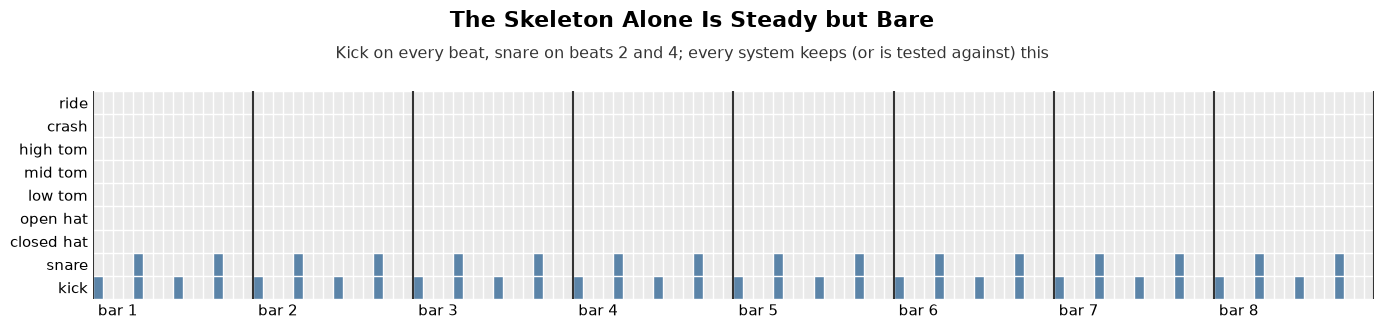

In [2]:
show_loop(skeleton_loop(), "The Skeleton Alone Is Steady but Bare",
          subtitle="Kick on every beat, snare on beats 2 and 4; every system keeps (or is tested against) this")

# 2. The data

TODO

# 3. Rule baseline (A)

TODO

# 4. Learned model

TODO

# 5. Adding constraints (C)

TODO

# 6. Experiment

TODO

# 7. Reflection

TODO